# Notebook Day 1 - Parkinson : EDA et baseline dummy

Equipe : Bob Le Bricoleur

Victor MICHELON, Bertrand MAIGRE, Jean-Baptiste PASTEAU, Oscar DUJARDIN

Le but est de prédire le score moteur OFF "débiaisé" (target) pour chaque visite de patient. Aujourd'hui on charge les données, on les explore un peu, puis on fait une baseline très simple (la moyenne) qui servira de référence.

## 1. Chargement des données

In [1]:
import pandas as pd

X_train = pd.read_csv("data/X_train.csv")
y_train = pd.read_csv("data/y_train.csv")
X_test = pd.read_csv("data/X_test.csv")

# une ligne = une visite, on associe chaque visite à sa target
visits = X_train.merge(y_train, on="Index")
y = visits["target"]

visits.head()

,Index,patient_id,cohort,sexM,gene,age_at_diagnosis,age,ledd,time_since_intake_on,time_since_intake_off,rater_id,on,off,target
0,0,IPLP5212,A,0,LRRK2+,48.5,52.1,607.0,1.9,NaN,R36,7.0,NaN,34.7
1,1,IPLP5212,A,0,LRRK2+,48.5,53.0,666.0,1.9,17.6,R43,11.0,40.0,38.1
2,2,IPLP5212,A,0,LRRK2+,48.5,53.9,717.0,1.2,NaN,R43,6.0,NaN,41.6
3,3,IPLP5212,A,0,LRRK2+,48.5,54.8,770.0,1.5,NaN,R36,12.0,NaN,44.9
4,4,IPLP5212,A,0,LRRK2+,48.5,56.9,885.0,0.3,NaN,R36,26.0,NaN,52.0


## 2. Exploration (EDA)

### Taille des tables et visites par patient

In [2]:
print("train :", X_train.shape[0], "visites,", X_train["patient_id"].nunique(), "patients")
print("test  :", X_test.shape[0], "visites,", X_test["patient_id"].nunique(), "patients")

visits_per_patient = X_train.groupby("patient_id").size()
print(visits_per_patient.describe())

train : 44590 visites, 5576 patients
test  : 11013 visites, 1395 patients
count    5576.000000
mean        7.996772
std         3.504563
min         4.000000
25%         4.000000
50%         7.000000
75%        12.000000
max        12.000000
dtype: float64


### Valeurs manquantes

In [3]:
missing = visits.isna().mean().sort_values(ascending=False)
print(missing)

print("\nPas de off :", visits["off"].isna().mean())
print("Pas de on  :", visits["on"].isna().mean())
print("Ni on ni off :", (visits["on"].isna() & visits["off"].isna()).sum(), "visites")

time_since_intake_off    0.787531
time_since_intake_on     0.463736
off                      0.424153
ledd                     0.366405
gene                     0.323660
on                       0.296479
age_at_diagnosis         0.052007
Index                    0.000000
patient_id               0.000000
cohort                   0.000000
sexM                     0.000000
age                      0.000000
rater_id                 0.000000
target                   0.000000
dtype: float64

Pas de off : 0.42415339762278537
Pas de on  : 0.29647903117290875
Ni on ni off : 0 visites


### Distribution de la target

count    44590.000000
mean        37.471527
std         16.499679
min          0.000000
25%         25.600000
50%         37.300000
75%         49.300000
max        109.500000
Name: target, dtype: float64
skew : 0.051060666356629314


<Axes: >

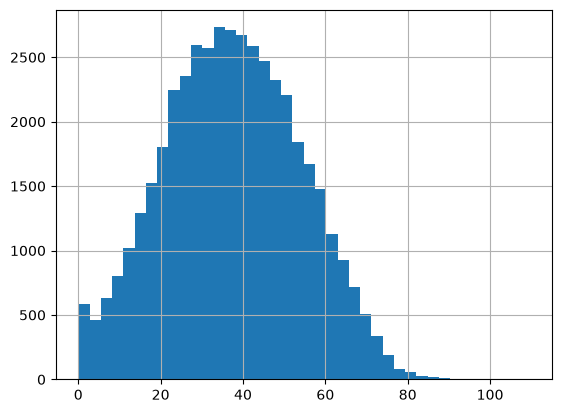

In [4]:
print(y.describe())
print("skew :", y.skew())
y.hist(bins=40)

### Corrélation avec la target

In [5]:
num_cols = visits.select_dtypes("number").columns
visits[num_cols].corr()["target"].sort_values(ascending=False)

target                   1.000000
off                      0.871191
on                       0.668735
age                      0.309816
ledd                     0.298093
age_at_diagnosis         0.133150
time_since_intake_off    0.008291
time_since_intake_on     0.000233
sexM                    -0.001394
Index                   -0.004239
Name: target, dtype: float64

### Les valeurs manquantes de ledd selon la cohorte

In [6]:
visits.groupby("cohort")["ledd"].apply(lambda s: s.isna().mean())

cohort
A    0.358967
B    0.425918
Name: ledd, dtype: float64

Quelques remarques :
- `off` est corrélé à la target mais pas identique (il est biaisé et souvent manquant).
- `ledd` n'est pas manquant au hasard, ça dépend de la cohorte (sûrement des protocoles différents selon les centres).
- Je n'utiliserai pas `Index` ni `patient_id` comme features : ce sont des identifiants et ça risque de faire fuiter de l'info. `target` bien sûr non plus.

## 3. Baseline dummy

Le modèle dummy prédit toujours la moyenne de la target. Il ne sert à rien en vrai mais donne le score minimum à battre.

In [7]:
from sklearn.dummy import DummyRegressor
from skore import evaluate

feature_cols = [
    "sexM",
    "age_at_diagnosis",
    "age",
    "ledd",
    "time_since_intake_on",
    "time_since_intake_off",
    "on",
    "off",
]
X = visits[feature_cols]

dummy = DummyRegressor(strategy="mean")
report = evaluate(dummy, X, y)
report.metrics.rmse()

16.477937440653164

In [8]:
# pour comparer avec l'écart-type de la target
y.std()

np.float64(16.49967897803254)

Le RMSE du dummy est quasiment égal à l'écart-type de `target`, ce qui est logique : prédire la moyenne revient à mesurer la dispersion autour de la moyenne.

### Envoi du rapport sur le hub

In [10]:
from skore import Project, login

login(mode="hub")
project = Project(name="bobathon-esilv", mode="hub", workspace="bob-le-bricoleur")  # à remplacer par le workspace du fichier .skore
project.put("01_dummy", report)

Output()

Output()

Consult your report at 
]8;id=1633129;https://skore.probabl.ai/bob-le-bricoleur/bobathon-esilv/estimators/89873\https://skore.probabl.ai/bob-le-bricoleur/bobathon-esilv/estimators/89873]8;;\